In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df = pd.read_csv(r"C:\Users\julia\Desktop\Modules\Week5\W5_Day2\amz_uk_price_prediction_dataset.csv")

In [2]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
#Part 1
#1.1
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
crosstab_result_sorted = pd.DataFrame(crosstab_result).sort_values(by=False, ascending=False)
crosstab_result_sorted

isBestSeller,False,True
category,,
Sports & Outdoors,835935,330
"Handmade Clothing, Shoes & Accessories",19215,14
Bath & Body,19059,33
Beauty,19010,302
Birthday Gifts,18943,35
...,...,...
Motorbike Chassis,107,0
Alexa Built-In Devices,106,1
Plugs,106,1


In [5]:
#Part 1
#1.2

crosstab_result_df = pd.DataFrame(crosstab_result)

crosstab_result_df["Proportion"] = crosstab_result_df[True]/(crosstab_result_df[True]+crosstab_result_df[False])

crosstab_result_df.sort_values(by="Proportion", ascending=False)

#No, there are not, the number of non-best sellers is always higher than the number of best sellers for all categories. 

isBestSeller,False,True,Proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Bedding Collections,6309,0,0.000000
CPUs,249,0,0.000000
"CD, Disc & Tape Players",8798,0,0.000000


In [6]:
#Part 1
#2.1

from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)

print(f"{chi2_p_value:.2f}")

#As p-value is zero, there is a statistically significant association between product category and whether an item is a best seller.

0.00


In [7]:
#Part 1
#2.2

from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

#As the df is 1 (2 columns), it is considered a small to moderate association. 

0.1222829439760564

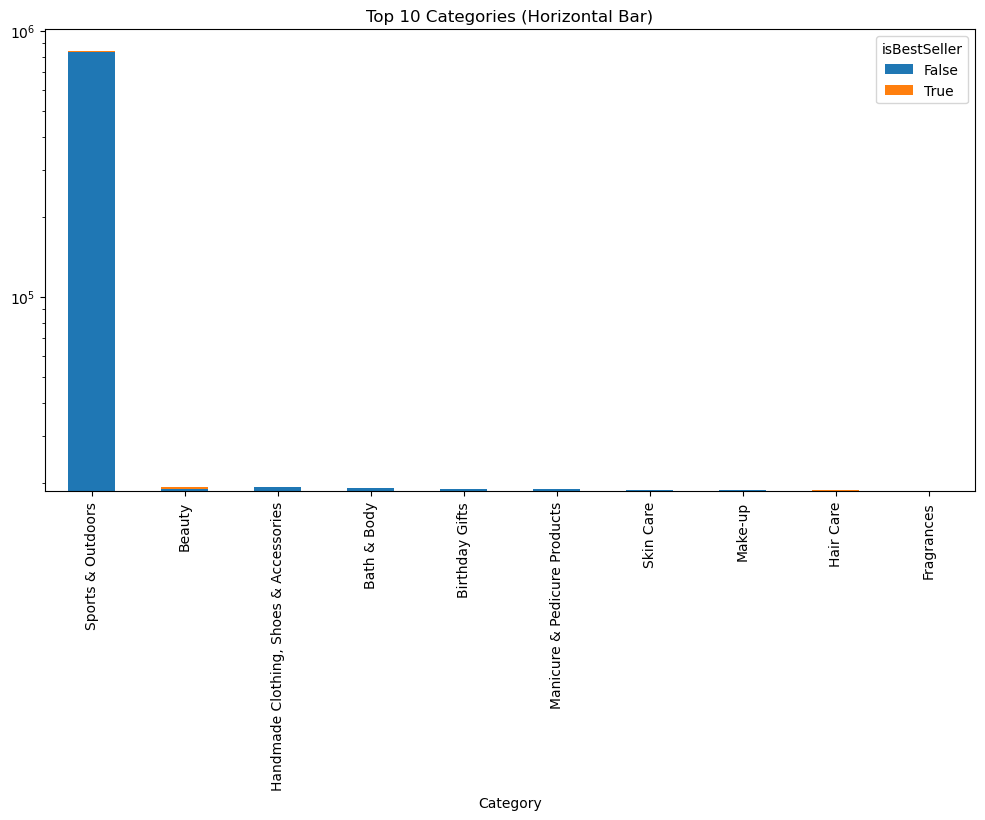

In [8]:
#Part 1
#3

crosstab_result_df_vis = pd.DataFrame(crosstab_result)
crosstab_result_df_vis["Total"] = crosstab_result_df_vis[True] + crosstab_result_df_vis[False]
top10 = crosstab_result_df_vis.nlargest(10, "Total")
top10.drop(columns=["Total"]).plot(kind="bar", stacked=True, figsize=(12,6), log=True)
plt.xlabel("Category")
plt.title("Top 10 Categories (Horizontal Bar)")
plt.show()

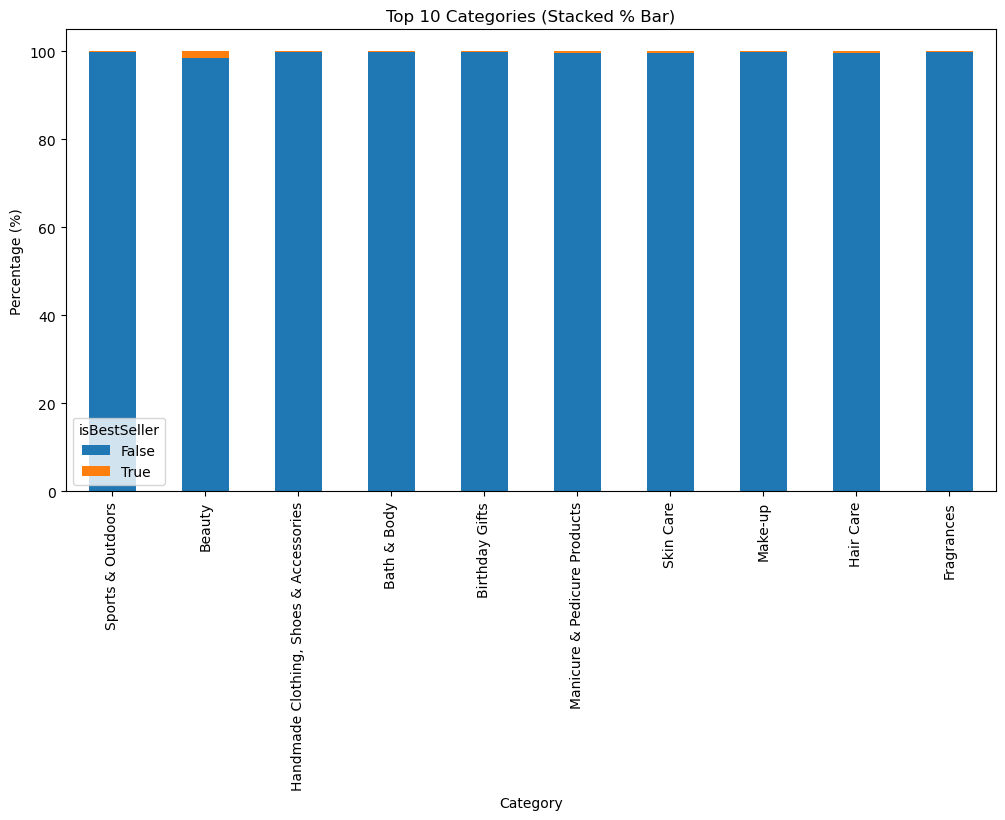

In [9]:
top10_perc = top10.drop(columns=["Total"]).div(top10["Total"], axis=0) * 100

top10_perc.plot(kind="bar", stacked=True, figsize=(12,6))

plt.xlabel("Category")
plt.ylabel("Percentage (%)")
plt.title("Top 10 Categories (Stacked % Bar)")
plt.show()

In [10]:
#Part 2
#0

def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [11]:
def tukeys_test_upper_lower(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    return lower_bound, upper_bound

In [12]:
df["price"].quantile(0.25)

np.float64(9.99)

In [13]:
df["price"].quantile(0.75)

np.float64(45.99)

In [14]:
tukeys_test_upper_lower(df["price"])

(np.float64(-44.01), np.float64(99.99000000000001))

In [15]:
def tukeys_filtered_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    data_filtered = data[(data > lower_bound) & (data < upper_bound)]

    return data_filtered

In [16]:
tukeys_test_outliers(df["price"])

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64

In [17]:
df_filtered_outliers = df[df["price"].isin(tukeys_filtered_outliers(df["price"]))]
df_filtered_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


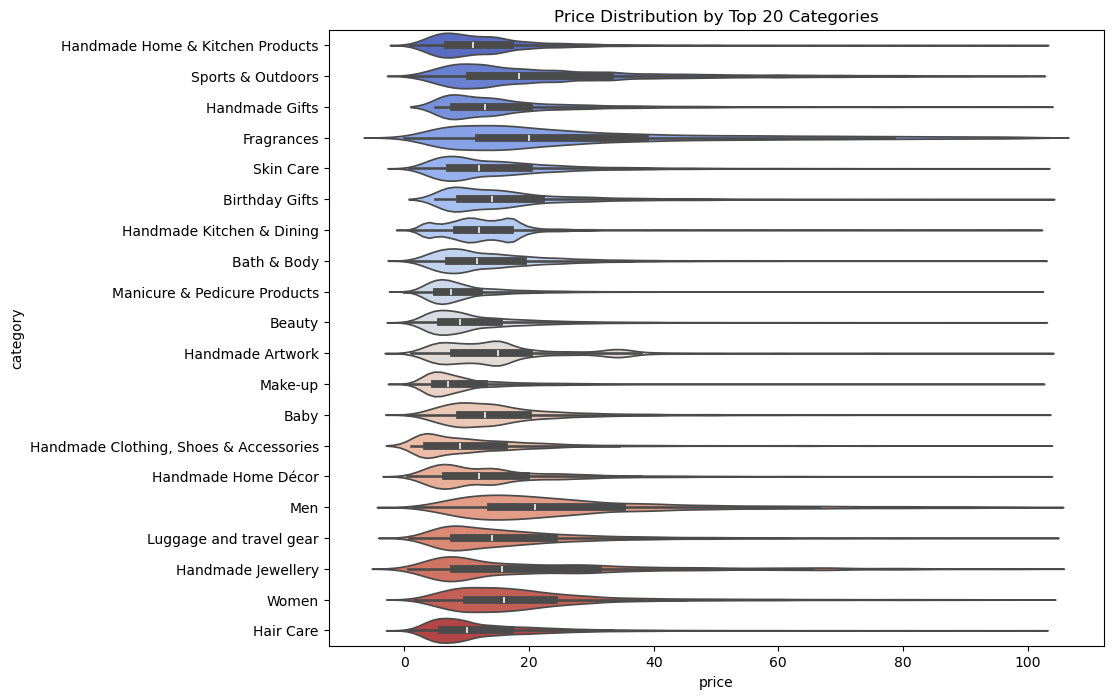

In [18]:
#Part 2
#1.1
#sns.violinplot(data=df, x='price', y='category', palette="coolwarm", hue='category', legend=False);
#plt.show()

top20_categories = df_filtered_outliers['category'].value_counts().nlargest(20).index

df_top20 = df_filtered_outliers[df_filtered_outliers['category'].isin(top20_categories)]

plt.figure(figsize=(10, 8))
sns.violinplot(data=df_top20, x='price', y='category', palette="coolwarm", hue='category')
plt.title("Price Distribution by Top 20 Categories")
plt.show()

In [19]:
#Part 2
#1.2
df_filtered_outliers.groupby("category")["price"].median().sort_values(ascending=False)

#Desktop PCs 

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

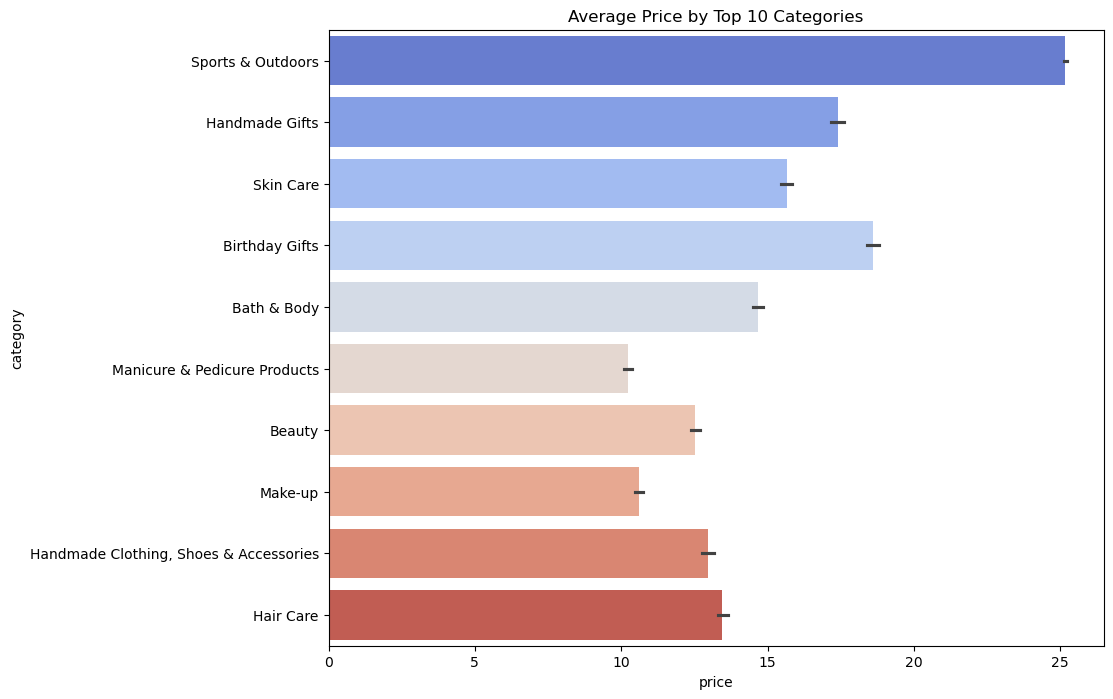

In [20]:
#Part 2
#2.1

top10_categories = df_filtered_outliers['category'].value_counts().nlargest(10).index

df_top10 = df_filtered_outliers[df_filtered_outliers['category'].isin(top10_categories)]

plt.figure(figsize=(10, 8))
sns.barplot(data=df_top10, x='price', y='category', palette="coolwarm", hue='category')
plt.title("Average Price by Top 10 Categories")
plt.show()

In [21]:
#Part 2
#2.2
df_filtered_outliers.groupby("category")["price"].mean().sort_values(ascending=False)

#Yes, Motherboards.

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

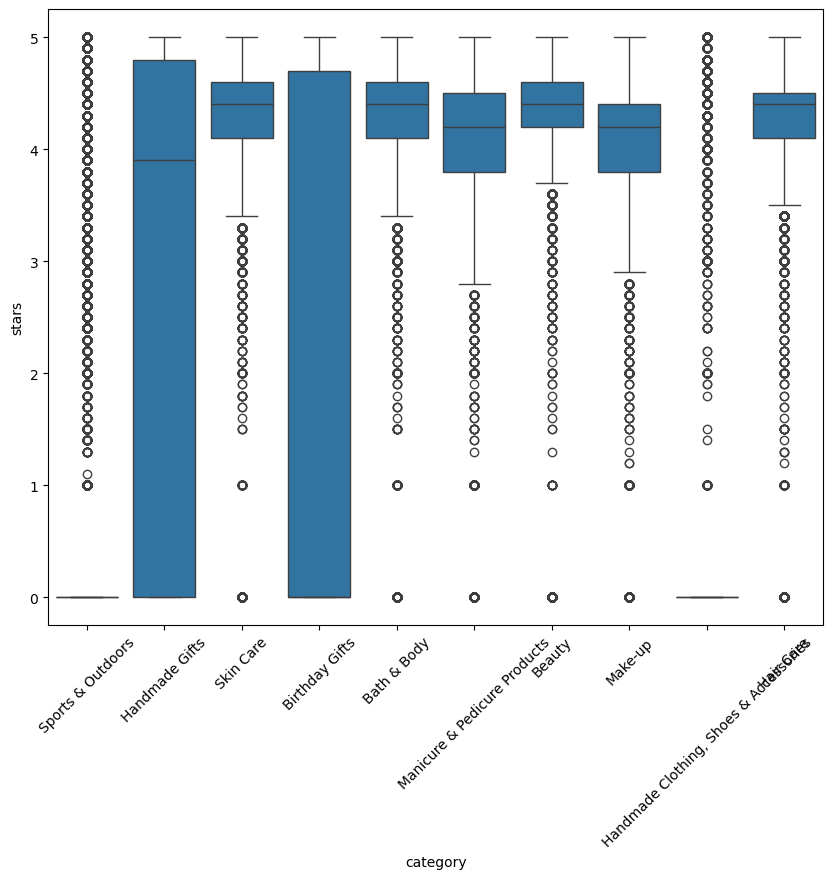

In [32]:
#Part 2
#3.1
top10_categories = df_filtered_outliers['category'].value_counts().nlargest(10).index

df_top10 = df_filtered_outliers[df_filtered_outliers['category'].isin(top10_categories)]

plt.figure(figsize=(10, 8))
plt.xticks(rotation=45)
sns.boxplot(data=df_top10, x='category', y='stars', legend=False);
plt.show()

In [34]:
#Part 2
#3.2
df_filtered_outliers.groupby("category")["stars"].median().sort_values(ascending=False)

#Computer Memory

category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

In [35]:
#Part 3
#1.1
corr_price_stars = df['price'].corr(df['stars'])
corr_price_stars

np.float64(-0.1249067326214861)

In [ ]:
#Part 3
#1.2
#No, but as the number is negative, the tendency is that it is inversaly proportional (even if the proportion is low). 

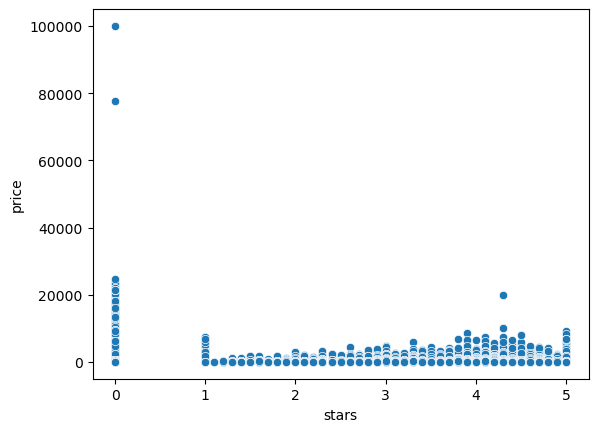

In [39]:
#Part 3
#2.1

sns.scatterplot(data=df, x='stars', y='price');
plt.show()

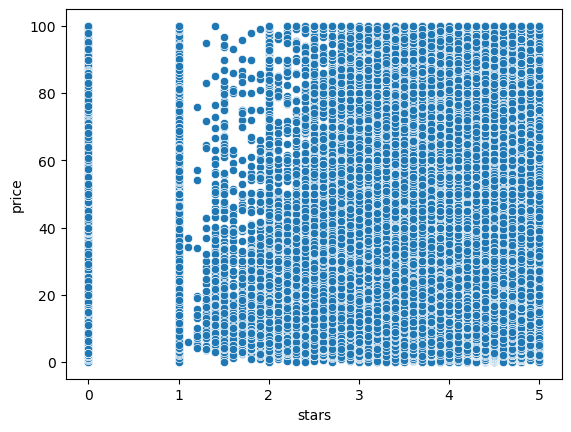

In [40]:
sns.scatterplot(data=df_filtered_outliers, x='stars', y='price');
plt.show()

In [ ]:
#Part 3
#2.1

#The peaks are on the low ratings and high ratings, showing that people usually love of hate the product. 

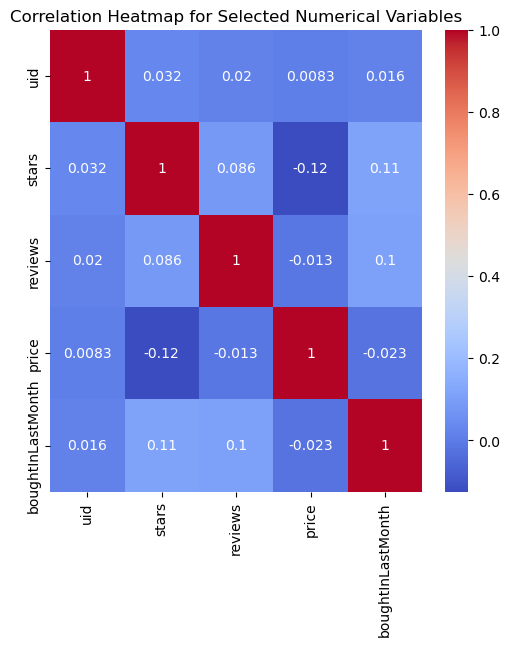

In [46]:
#Part 3
#2.2
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

spearman_correlations = df_numerical.corr(method='spearman')

correlation_matrix = df_numerical[spearman_correlations.index].corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(6, 6))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

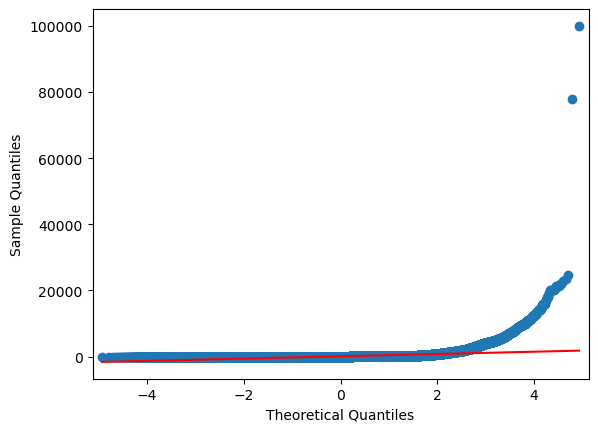

In [48]:
#Part 3
#2.3
import statsmodels.api as sm

sm.qqplot(df['price'], line='s');
plt.show()

In [ ]:
#Part 3
#2.3
#Prices do not follow a normal distribution, as they are right-skewed and have some extreme outliers.